In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('load_data.csv')
print(df.shape)
df.head()

(35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [44]:
print(list(df.columns))
df.info()

['Date_Time', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'Load_Type']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  object 
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type    

In [45]:
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())

Date_Time                                  0
Usage_kWh                               1559
Lagging_Current_Reactive.Power_kVarh     876
Leading_Current_Reactive_Power_kVarh    1156
CO2(tCO2)                                455
Lagging_Current_Power_Factor             350
Leading_Current_Power_Factor            1471
NSM                                      455
Load_Type                                  0
dtype: int64
Duplicates: 0


In [46]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Usage_kWh,33482.0,30.873061,41.415015,0.0,3.310,5.29,53.560000,435.019069
Lagging_Current_Reactive.Power_kVarh,34165.0,14.704573,20.342721,0.0,2.340,5.18,23.510000,262.630718
Leading_Current_Reactive_Power_kVarh,33885.0,4.386097,9.090181,0.0,0.000,0.00,2.298558,78.809000
CO2(tCO2),34586.0,0.012947,0.019726,0.0,0.000,0.00,0.020000,0.188166
Lagging_Current_Power_Factor,34691.0,90.740871,39.745395,0.0,66.295,90.08,100.000000,299.996814
Leading_Current_Power_Factor,33570.0,94.926552,49.826872,0.0,99.800,100.00,100.000000,299.969494
NSM,34586.0,48013.664032,34046.492333,0.0,22500.000,45000.00,68400.000000,248821.810465


In [47]:
df['Date_Time'] = pd.to_datetime(df['Date_Time'], format='%d-%m-%Y %H:%M', errors='coerce')
print('Unparsed dates:', df['Date_Time'].isna().sum())
df = df.sort_values('Date_Time').reset_index(drop=True)
print(df['Date_Time'].min(), '->', df['Date_Time'].max())

Unparsed dates: 0
2018-01-01 00:00:00 -> 2018-12-31 23:45:00


In [48]:
print(df['Load_Type'].value_counts())
print(df['Load_Type'].value_counts(normalize=True).round(3))

Load_Type
Light_Load      18073
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64
Load_Type
Light_Load      0.516
Medium_Load     0.277
Maximum_Load    0.208
Name: proportion, dtype: float64


In [49]:
expected_nsm = df['Date_Time'].dt.hour * 3600 + df['Date_Time'].dt.minute * 60
print('NSM > 86400:', (df['NSM'] > 86400).sum())
print('NSM != time of day:', ((df['NSM'] != expected_nsm) & df['NSM'].notna()).sum())
print('Lagging PF > 100:', (df['Lagging_Current_Power_Factor'] > 100).sum())
print('Leading PF > 100:', (df['Leading_Current_Power_Factor'] > 100).sum())

NSM > 86400: 1773
NSM != time of day: 3414
Lagging PF > 100: 3226
Leading PF > 100: 2685


In [50]:
dup = df[df['Date_Time'].duplicated(keep=False)]
dup

,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
35024,2018-12-31 20:00:00,NaN,0.0,20.10,0.0,217.27347,20.19,72000.0,Light_Load
35025,2018-12-31 20:00:00,4.14,0.0,20.09,0.0,100.00000,20.18,72000.0,Light_Load


In [51]:
df.groupby('Load_Type')['Usage_kWh'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Load_Type,,,,,,,,
Light_Load,17279.0,9.73,21.82,0.00,2.99,3.42,4.68,304.71
Maximum_Load,6958.0,66.95,42.24,2.92,43.86,58.90,87.06,401.78
Medium_Load,9245.0,43.24,44.85,2.52,4.75,35.93,65.41,435.02


In [52]:
df = (df.assign(n_missing=df.isna().sum(axis=1))
        .sort_values(['Date_Time', 'n_missing'])
        .drop_duplicates(subset='Date_Time', keep='first')
        .drop(columns='n_missing')
        .reset_index(drop=True))
print(df.shape)

(35040, 9)


In [53]:
df['hour'] = df['Date_Time'].dt.hour
df['minute'] = df['Date_Time'].dt.minute
minutes = df['hour'] * 60 + df['minute']

df['tod_sin'] = np.sin(2 * np.pi * minutes / 1440)
df['tod_cos'] = np.cos(2 * np.pi * minutes / 1440)

df['dayofweek'] = df['Date_Time'].dt.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

df = df.drop(columns='NSM')

    hour  tod_sin  tod_cos
0      0      0.0      1.0
24     6      1.0      0.0
48    12      0.0     -1.0
72    18     -1.0     -0.0


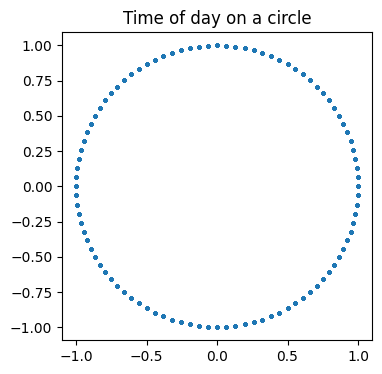

In [54]:
#checking wether the cyclical encoding worked
chk = df[df['minute'].eq(0) & df['hour'].isin([0, 6, 12, 18])]
print(chk.drop_duplicates('hour')[['hour', 'tod_sin', 'tod_cos']].round(2))

plt.figure(figsize=(4, 4))
plt.scatter(df['tod_cos'], df['tod_sin'], s=3)
plt.axis('equal'); plt.title('Time of day on a circle'); plt.show()

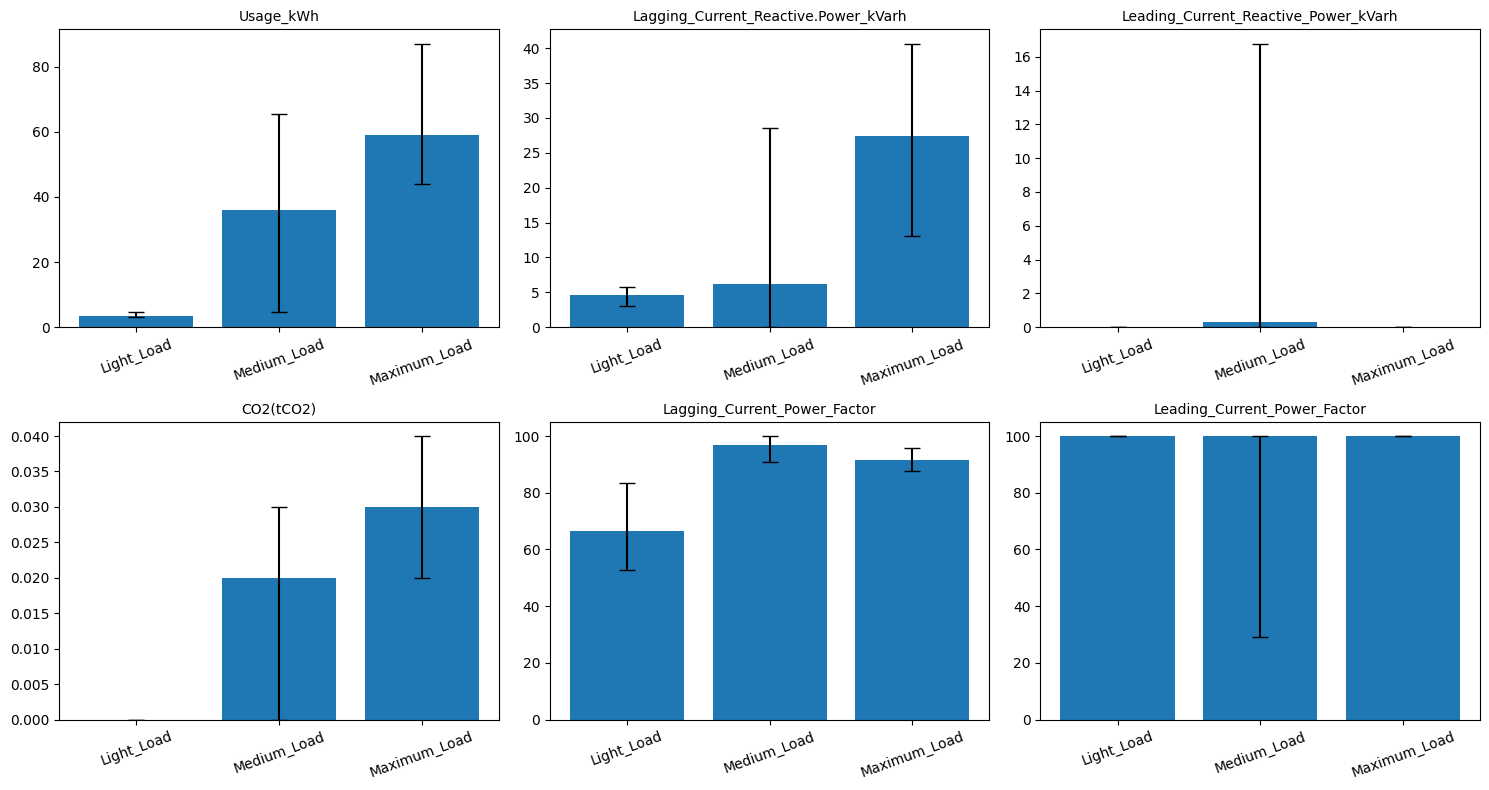

In [55]:
num_cols = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
            'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
            'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']
order = ['Light_Load', 'Medium_Load', 'Maximum_Load']

tmp = df.copy()
for c in ['Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']:
    tmp.loc[tmp[c] > 100, c] = np.nan

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), num_cols):
    g = tmp.groupby('Load_Type')[c]
    med = g.median().reindex(order)
    q1 = g.quantile(0.25).reindex(order)
    q3 = g.quantile(0.75).reindex(order)
    ax.bar(order, med, yerr=[med - q1, q3 - med], capsize=6)
    ax.set_title(c, fontsize=10)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

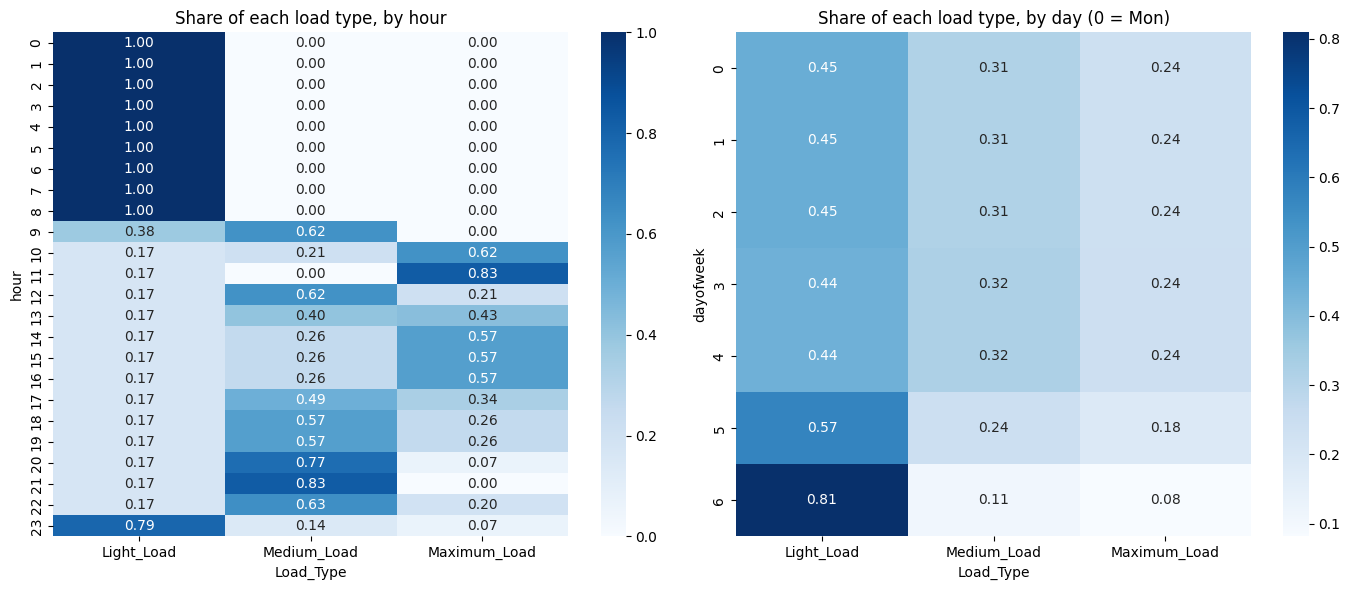

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(pd.crosstab(df['hour'], df['Load_Type'], normalize='index')[order],
            annot=True, fmt='.2f', cmap='Blues', ax=axes[0])
axes[0].set_title('Share of each load type, by hour')

sns.heatmap(pd.crosstab(df['dayofweek'], df['Load_Type'], normalize='index')[order],
            annot=True, fmt='.2f', cmap='Blues', ax=axes[1])
axes[1].set_title('Share of each load type, by day (0 = Mon)')
plt.tight_layout(); plt.show()

In [57]:
print(df.shape)

(35040, 14)


In [58]:
for c in ['Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']:
    df.loc[df[c] > 100, c] = np.nan

miss = df.isna().sum().to_frame('missing')
miss['pct'] = (100 * miss['missing'] / len(df)).round(1)
miss

,missing,pct
Date_Time,0,0.0
Usage_kWh,1558,4.4
Lagging_Current_Reactive.Power_kVarh,876,2.5
Leading_Current_Reactive_Power_kVarh,1156,3.3
CO2(tCO2),455,1.3
Lagging_Current_Power_Factor,3575,10.2
Leading_Current_Power_Factor,4156,11.9
Load_Type,0,0.0
hour,0,0.0
minute,0,0.0


In [59]:
#About 4,400 rows have a stored power factor that disagrees with the value calculated from usage and reactive power,
#so at least one of those three values is corrupted in each of them.
cols = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Lagging_Current_Power_Factor']
s = df[cols].dropna().copy()
s['pf_calc'] = 100 * s['Usage_kWh'] / np.sqrt(s['Usage_kWh']**2 + s['Lagging_Current_Reactive.Power_kVarh']**2)
bad = s[(s['pf_calc'] - s['Lagging_Current_Power_Factor']).abs() >= 0.5]
print(len(bad), 'mismatched rows')
bad.head(10).round(2)

4437 mismatched rows


,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Lagging_Current_Power_Factor,pf_calc
1,8.75,2.95,73.21,94.76
9,5.93,3.64,66.94,85.23
20,3.31,10.54,67.68,29.95
22,3.56,7.68,65.56,42.04
25,3.35,7.11,67.72,42.62
32,3.31,11.28,65.88,28.16
90,3.67,6.98,65.71,46.54
93,3.53,9.61,71.82,34.47
108,3.28,8.11,66.24,37.51
109,3.71,8.80,97.96,38.83


In [60]:
num_cols = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
            'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
            'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']

long_dec = pd.DataFrame({c: df[c].notna() & (df[c].round(2) != df[c]) for c in num_cols})
print(long_dec.sum())
print('Rows with at least one long-decimal value:', long_dec.any(axis=1).sum())

Usage_kWh                               3358
Lagging_Current_Reactive.Power_kVarh    2710
Leading_Current_Reactive_Power_kVarh    1137
CO2(tCO2)                               1369
Lagging_Current_Power_Factor             235
Leading_Current_Power_Factor             661
dtype: int64
Rows with at least one long-decimal value: 8622


In [61]:
cols = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Lagging_Current_Power_Factor']
s = df[cols].dropna().copy()
pf_calc = 100 * s['Usage_kWh'] / np.sqrt(s['Usage_kWh']**2 + s['Lagging_Current_Reactive.Power_kVarh']**2)
s['mismatch'] = (pf_calc - s['Lagging_Current_Power_Factor']).abs() >= 0.5
s['any_long'] = long_dec.loc[s.index, cols].any(axis=1)

print(pd.crosstab(s['any_long'], s['mismatch'], normalize='index').round(3))

mismatch  False  True 
any_long              
False     1.000  0.000
True      0.155  0.845


In [62]:
df_clean = df.copy()

for c in num_cols:
    bad = df_clean[c].notna() & (df_clean[c].round(2) != df_clean[c])
    df_clean.loc[bad, c] = np.nan

miss = df_clean[num_cols].isna().sum().to_frame('missing')
miss['pct'] = (100 * miss['missing'] / len(df_clean)).round(1)
miss

,missing,pct
Usage_kWh,4916,14.0
Lagging_Current_Reactive.Power_kVarh,3586,10.2
Leading_Current_Reactive_Power_kVarh,2293,6.5
CO2(tCO2),1824,5.2
Lagging_Current_Power_Factor,3810,10.9
Leading_Current_Power_Factor,4817,13.7


In [63]:
lead = ['Usage_kWh', 'Leading_Current_Reactive_Power_kVarh', 'Leading_Current_Power_Factor']
t = df_clean[lead].dropna().copy()
pf_calc = 100 * t['Usage_kWh'] / np.sqrt(t['Usage_kWh']**2 + t['Leading_Current_Reactive_Power_kVarh']**2)
print('Leading PF formula match:', ((pf_calc - t['Leading_Current_Power_Factor']).abs() < 0.5).mean().round(3))

Leading PF formula match: 1.0


In [64]:
def pf_from(U, R):
    denom = np.sqrt(U**2 + R**2)
    return (100 * U / denom.where(denom > 0)).round(2)

for pf_col, r_col in [('Lagging_Current_Power_Factor', 'Lagging_Current_Reactive.Power_kVarh'),
                      ('Leading_Current_Power_Factor', 'Leading_Current_Reactive_Power_kVarh')]:
    est = pf_from(df_clean['Usage_kWh'], df_clean[r_col])
    known = df_clean[pf_col].notna() & est.notna()
    err = (est[known] - df_clean.loc[known, pf_col]).abs()
    print(pf_col, '-> max error:', round(err.max(), 3), '| mean error:', round(err.mean(), 4))


Lagging_Current_Power_Factor -> max error: 0.0 | mean error: 0.0
Leading_Current_Power_Factor -> max error: 0.0 | mean error: 0.0


In [65]:
before = df_clean[['Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']].isna().sum()

for pf_col, r_col in [('Lagging_Current_Power_Factor', 'Lagging_Current_Reactive.Power_kVarh'),
                      ('Leading_Current_Power_Factor', 'Leading_Current_Reactive_Power_kVarh')]:
    est = pf_from(df_clean['Usage_kWh'], df_clean[r_col])
    df_clean[pf_col] = df_clean[pf_col].fillna(est)

after = df_clean[['Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']].isna().sum()
print(pd.DataFrame({'before': before, 'after': after}))

                              before  after
Lagging_Current_Power_Factor    3810    849
Leading_Current_Power_Factor    4817    938


In [66]:
pf = 'Lagging_Current_Power_Factor'
r = 'Lagging_Current_Reactive.Power_kVarh'
cols = ['Usage_kWh', r, pf]

print('Rows where PF is still missing:')
print(df_clean[df_clean[pf].isna()][cols].head(5))
print('\nHow many of those have usage missing / reactive missing:')
still = df_clean[df_clean[pf].isna()]
print('usage missing:', still['Usage_kWh'].isna().sum(), '| reactive missing:', still[r].isna().sum())

Rows where PF is still missing:
     Usage_kWh  Lagging_Current_Reactive.Power_kVarh  \
29        3.28                                   NaN   
69         NaN                                   0.0   
70         NaN                                   0.0   
86         NaN                                   0.0   
109       3.71                                   NaN   

     Lagging_Current_Power_Factor  
29                            NaN  
69                            NaN  
70                            NaN  
86                            NaN  
109                           NaN  

How many of those have usage missing / reactive missing:
usage missing: 543 | reactive missing: 355


In [67]:
# d = df_clean.copy()


# d['minutes']   = d['hour'] * 60 + d['minute']
# d['month']     = d['Date_Time'].dt.month
# d['month_sin'] = np.sin(2 * np.pi * d['month'] / 12)
# d['month_cos'] = np.cos(2 * np.pi * d['month'] / 12)

# U, L, R = 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh'
# d['apparent_power'] = np.sqrt(d[U]**2 + d[L]**2)
# d['total_reactive'] = d[L] + d[R]

# FEATURES = [U, L, R, 'CO2(tCO2)', 'apparent_power', 'total_reactive',
#             'minutes', 'tod_sin', 'tod_cos', 'dayofweek', 'is_weekend',
#             'month_sin', 'month_cos']
# TARGET = 'Load_Type'

# train_df = d[d['Date_Time'] <  '2018-12-01']
# test_df  = d[d['Date_Time'] >= '2018-12-01']
# X_train, y_train = train_df[FEATURES], train_df[TARGET]
# X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]
# print(X_train.shape, X_test.shape)

In [68]:
d = df_clean.copy()

d['minutes']   = d['hour'] * 60 + d['minute']
d['month']     = d['Date_Time'].dt.month
d['month_sin'] = np.sin(2 * np.pi * d['month'] / 12)
d['month_cos'] = np.cos(2 * np.pi * d['month'] / 12)

U, L, R = 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh'
d['apparent_power'] = np.sqrt(d[U]**2 + d[L]**2)
d['total_reactive'] = d[L] + d[R]

d['date'] = d['Date_Time'].dt.date
g = d.groupby('date')[U]
d['day_median_usage'] = g.transform('median')
d['day_max_usage']    = g.transform('max')

FEATURES = [U, L, R, 'CO2(tCO2)', 'apparent_power', 'total_reactive',
            'minutes', 'tod_sin', 'tod_cos', 'dayofweek', 'is_weekend',
            'month_sin', 'month_cos', 'day_median_usage', 'day_max_usage']
TARGET = 'Load_Type'

train_df = d[d['Date_Time'] <  '2018-12-01']
test_df  = d[d['Date_Time'] >= '2018-12-01']
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]
print(X_train.shape, X_test.shape)

(32064, 15) (2976, 15)


In [69]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

le = LabelEncoder().fit(y_train)
y_tr, y_te = le.transform(y_train), le.transform(y_test)

results, probas = [], {}

def evaluate(name, model, report=False):
    model.fit(X_train, y_tr)
    proba = model.predict_proba(X_test)
    pred = proba.argmax(axis=1)
    p, r, f, _ = precision_recall_fscore_support(y_te, pred, average='macro', zero_division=0)
    results.append({'model': name, 'accuracy': accuracy_score(y_te, pred),
                    'precision': p, 'recall': r, 'f1_macro': f})
    probas[name] = proba
    if report:
        print(classification_report(y_te, pred, target_names=le.classes_, digits=3))

impute = lambda: SimpleImputer(strategy='median')
models = {
    'Logistic Regression': make_pipeline(impute(), StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'Random Forest': make_pipeline(impute(), RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=42)),
    'XGBoost': XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, random_state=42),
    'LightGBM': LGBMClassifier(n_estimators=400, learning_rate=0.05, class_weight='balanced', random_state=42, verbose=-1),
}
for name, m in models.items():
    evaluate(name, m)


blend = (probas['Random Forest'] + probas['XGBoost'] + probas['LightGBM']) / 3
pred = blend.argmax(axis=1)
p, r, f, _ = precision_recall_fscore_support(y_te, pred, average='macro', zero_division=0)
results.append({'model': 'Blend (RF+XGB+LGBM)', 'accuracy': accuracy_score(y_te, pred),
                'precision': p, 'recall': r, 'f1_macro': f})

pd.DataFrame(results).sort_values('f1_macro', ascending=False).round(4).reset_index(drop=True)

,model,accuracy,precision,recall,f1_macro
0,LightGBM,0.9906,0.9890,0.9917,0.9903
1,Blend (RF+XGB+LGBM),0.9896,0.9867,0.9914,0.9890
2,XGBoost,0.9862,0.9804,0.9899,0.9850
3,Random Forest,0.9856,0.9799,0.9888,0.9842
4,Logistic Regression,0.7201,0.5728,0.5654,0.5656


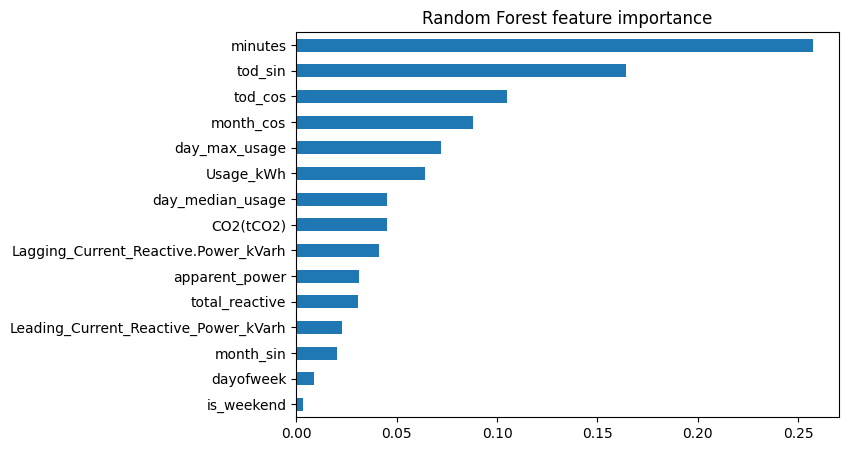

pred          Light_Load  Maximum_Load  Medium_Load
Load_Type                                          
Light_Load          1711            19           14
Maximum_Load           1           527            0
Medium_Load            9             0          695

Error rate by hour:
 hour
0     0.00
1     0.00
2     0.00
3     0.00
4     0.00
5     0.00
6     0.00
7     0.00
8     0.00
9     0.01
10    0.00
11    0.02
12    0.03
13    0.01
14    0.01
15    0.03
16    0.05
17    0.04
18    0.03
19    0.03
20    0.03
21    0.03
22    0.02
23    0.00

Worst 5 days:
 Date_Time
2018-12-29    0.34
2018-12-01    0.10
2018-12-02    0.00
2018-12-04    0.00
2018-12-05    0.00
Name: wrong, dtype: float64


In [70]:
rf = models['Random Forest'][-1]
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh(figsize=(7, 5))
plt.title('Random Forest feature importance'); plt.show()

res = test_df.copy()
res['pred'] = le.inverse_transform(probas['Random Forest'].argmax(axis=1))
res['wrong'] = res['pred'] != res[TARGET]

print(pd.crosstab(res[TARGET], res['pred']))
print('\nError rate by hour:\n', res.groupby('hour')['wrong'].mean().round(2).to_string())
print('\nWorst 5 days:\n', res.groupby(res['Date_Time'].dt.date)['wrong'].mean().sort_values(ascending=False).head(5).round(2))

In [71]:
w = d[d['month'].isin([1, 2, 11])].copy()
w['day_type'] = np.where(w['dayofweek'] < 5, 'Mon-Fri', np.where(w['dayofweek'] == 5, 'Sat', 'Sun'))
w['is_light'] = (w['Load_Type'] == 'Light_Load').astype(int)
pd.crosstab(w['hour'], w['day_type'], values=w['is_light'], aggfunc='mean').round(2)

day_type,Mon-Fri,Sat,Sun
hour,,,
0,1.00,1.00,1.00
1,1.00,1.00,1.00
2,1.00,1.00,1.00
3,1.00,1.00,1.00
4,1.00,1.00,1.00
5,1.00,1.00,1.00
6,1.00,1.00,1.00
7,1.00,1.00,1.00
8,1.00,1.00,1.00


In [72]:
we = d[(d['dayofweek'] >= 5) & d['hour'].between(10, 22)].copy()
we['is_light'] = (we['Load_Type'] == 'Light_Load').astype(int)
daily = we.groupby([we['Date_Time'].dt.date, 'dayofweek'])['is_light'].mean().round(2).reset_index()
daily.columns = ['date', 'dayofweek', 'light_share']

print(daily['light_share'].value_counts().head(6))
print(daily[daily['date'].astype(str) >= '2018-11-01'].to_string(index=False))

light_share
0.0    55
1.0    49
Name: count, dtype: int64
      date  dayofweek  light_share
2018-11-03          5          0.0
2018-11-04          6          0.0
2018-11-10          5          0.0
2018-11-11          6          1.0
2018-11-17          5          0.0
2018-11-18          6          0.0
2018-11-24          5          1.0
2018-11-25          6          1.0
2018-12-01          5          0.0
2018-12-02          6          1.0
2018-12-08          5          0.0
2018-12-09          6          1.0
2018-12-15          5          1.0
2018-12-16          6          0.0
2018-12-22          5          1.0
2018-12-23          6          1.0
2018-12-29          5          1.0
2018-12-30          6          1.0


In [73]:
# Check wether if all-Light weekend days have different usage from the others
we = d[(d['dayofweek'] >= 5) & d['hour'].between(10, 22)].copy()
we['is_light'] = (we['Load_Type'] == 'Light_Load').astype(int)
daily = we.groupby(we['Date_Time'].dt.date).agg(
    light_share=('is_light', 'mean'),
    median_usage=('Usage_kWh', 'median'),
    usage_readings=('Usage_kWh', 'count'))
print(daily.groupby('light_share')['median_usage'].describe().round(1))

# Check on weekdays that behave like Light days are maybe holidays
wk = d[(d['dayofweek'] < 5) & d['hour'].between(10, 22)].copy()
wk['is_light'] = (wk['Load_Type'] == 'Light_Load').astype(int)
wd = wk.groupby(wk['Date_Time'].dt.date)['is_light'].mean()
print('\nWeekdays that are mostly Light:')
print(wd[wd > 0.5].round(2).to_string())

             count  mean   std  min  25%  50%   75%   max
light_share                                              
0.0           55.0  15.6  15.3  3.5  4.3  6.9  24.3  76.2
1.0           49.0   3.4   0.5  2.7  3.0  3.2   3.6   5.0

Weekdays that are mostly Light:
Date_Time
2018-01-01    1.0
2018-02-14    1.0
2018-02-15    1.0
2018-02-16    1.0
2018-05-01    1.0
2018-08-01    1.0
2018-08-02    1.0
2018-08-03    1.0
2018-09-24    1.0
2018-09-25    1.0
2018-09-26    1.0
2018-12-25    1.0
2018-12-31    1.0
